In [3]:
# import libraries

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score




In [5]:
df_train = pd.read_csv('C:/Users/saqla/Desktop/ML_Project/Data/train-test.csv')

In [6]:
df_train.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [7]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  str    
 1   pickup        48000 non-null  str    
 2   delivery      48000 non-null  str    
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  str    
 9   weight        47700 non-null  float64
 10  date          48000 non-null  str    
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), str(5)
memory usage: 5.1 MB


In [8]:
df_train.describe().T

,count,mean,std,min,25%,50%,75%,max
pickup_lat,48000.0,35.647545,4.315285,28.35765,31.98691,35.29479,39.411040,44.30296
pickup_lon,48000.0,-90.928964,13.482431,-121.69849,-98.40059,-88.08915,-83.285060,-69.50000
delivery_lat,48000.0,35.641175,4.317199,28.35765,31.98691,35.29479,39.411040,44.30296
delivery_lon,48000.0,-90.857310,13.476589,-121.69849,-98.40059,-87.52871,-83.285060,-69.50000
distance,48000.0,1135.856654,728.564416,70.00000,550.40000,953.30000,1645.525000,3439.80000
weight,47700.0,31028.844004,9391.440620,-47500.00000,25800.00000,31436.50000,37018.000000,47500.00000
market_index,47626.0,1.083387,0.168091,0.67639,0.94967,1.05580,1.219590,1.46778
quote_signal,48000.0,2.062468,0.291391,0.69228,1.89103,2.05575,2.221685,3.61035
posted_rate,48000.0,2373.980682,1486.493245,57.22000,1251.55500,2030.76000,3330.750000,25533.00000


In [9]:

print("Total Duplicate Rows:", df_train.duplicated().sum())


Total Duplicate Rows: 0


In [10]:
print(df_train.isnull().sum()/len(df_train)*100)


load_id         0.000000
pickup          0.000000
delivery        0.000000
pickup_lat      0.000000
pickup_lon      0.000000
delivery_lat    0.000000
delivery_lon    0.000000
distance        0.000000
equipment       0.000000
weight          0.625000
date            0.000000
market_index    0.779167
quote_signal    0.000000
posted_rate     0.000000
dtype: float64


In [11]:

# Weight aur market_index ki missing values
# median se fill karenge

df_train["weight"] = df_train["weight"].fillna(df_train["weight"].median())

df_train["market_index"] = df_train["market_index"].fillna(
    df_train["market_index"].median()
)

# Dobara check karo
print("Missing values after cleaning:")
print(df_train.isnull().sum())


Missing values after cleaning:
load_id         0
pickup          0
delivery        0
pickup_lat      0
pickup_lon      0
delivery_lat    0
delivery_lon    0
distance        0
equipment       0
weight          0
date            0
market_index    0
quote_signal    0
posted_rate     0
dtype: int64


In [12]:

# Date ko datetime format mein convert karo
df_train["date"] = pd.to_datetime(df_train["date"], errors="coerce")

# Date se naye features
df_train["year"] = df_train["date"].dt.year
df_train["month"] = df_train["date"].dt.month
df_train["day"] = df_train["date"].dt.day
df_train["day_of_week"] = df_train["date"].dt.dayofweek

# Check karo
print(df_train[["date", "year", "month", "day", "day_of_week"]].head())


        date  year  month  day  day_of_week
0 2025-01-01  2025      1    1            2
1 2025-01-01  2025      1    1            2
2 2025-01-01  2025      1    1            2
3 2025-01-01  2025      1    1            2
4 2025-01-01  2025      1    1            2


In [13]:

# Target: jis rate ko predict karna hai
y = df_train["posted_rate"]

# Features: jin ki madad se prediction hogi
X = df_train.drop(columns=["posted_rate", "load_id", "date"])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())


Features shape: (48000, 15)
Target shape: (48000,)

Feature columns:
['pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'market_index', 'quote_signal', 'year', 'month', 'day', 'day_of_week']


In [14]:

# Date ke hisaab se data sort karo
df_train = df_train.sort_values("date").reset_index(drop=True)

# Features aur target dobara banao
y = df_train["posted_rate"]
X = df_train.drop(columns=["posted_rate", "load_id", "date"])

# Pehle 80% records training ke liye
split_point = int(len(df_train) * 0.80)

X_train = X.iloc[:split_point]
X_test = X.iloc[split_point:]

y_train = y.iloc[:split_point]
y_test = y.iloc[split_point:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 38400
Testing rows: 9600


In [15]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.ensemble import RandomForestRegressor

# Numeric aur categorical columns
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

# Numeric missing values
num_pipeline = Pipeline([
    ("imputer", KNNImputer(n_neighbors=5))
])

# Categorical missing values aur encoding
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore",sparse_output=False) )
])

# Dono pipelines combine
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

# Complete model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Model train karo
model.fit(X_train, y_train)

print("Model training complete!")


Model training complete!


In [16]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Five models
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    ),

    # "Gradient Boosting": HistGradientBoostingRegressor(
    #     max_iter=150,
    #     learning_rate=0.08,
    #     max_leaf_nodes=31,
    #     random_state=42
    # )
}

results = []
trained_models = {}

for name, regressor in models.items():
    # Har model ke liye preprocessing ki separate copy
    current_model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("regressor", regressor)
    ])

    print(f"Training: {name}")

    current_model.fit(X_train, y_train)
    predictions = current_model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = current_model

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("MAE").reset_index(drop=True)

print("\nModel Comparison:")
display(results_df.round(3))

print("\nBest model according to MAE:",
      results_df.loc[0, "Model"])


Training: Linear Regression
Training: Ridge Regression
Training: Random Forest
Training: Extra Trees

Model Comparison:


,Model,MAE,RMSE,R2 Score
0,Ridge Regression,142.763,637.580,0.825
1,Linear Regression,142.797,637.590,0.825
2,Random Forest,154.591,672.004,0.806
3,Extra Trees,170.903,724.976,0.774



Best model according to MAE: Ridge Regression


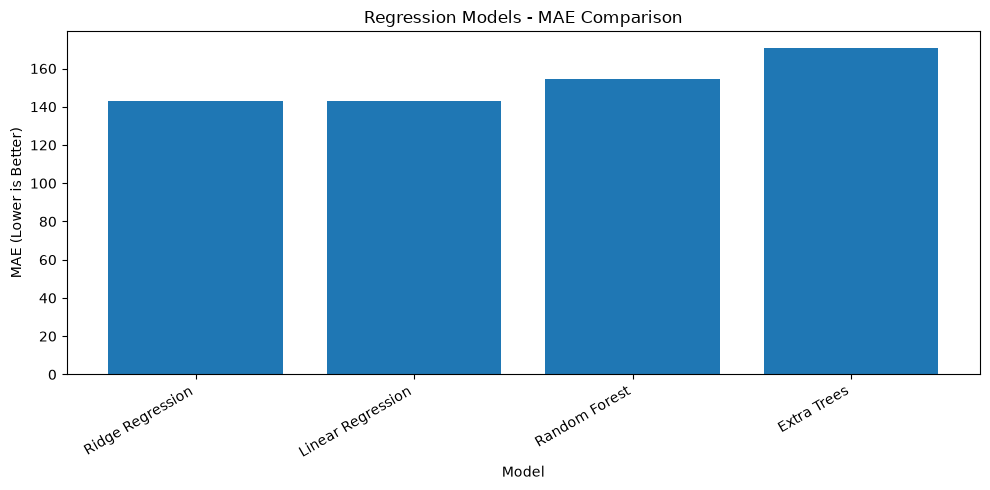

In [17]:

import matplotlib.pyplot as plt

# Models ka MAE comparison
plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["MAE"])
plt.title("Regression Models - MAE Comparison")
plt.xlabel("Model")
plt.ylabel("MAE (Lower is Better)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [18]:

# Sab se kam MAE wala model select karo
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

# Test data par predictions
best_predictions = best_model.predict(X_test)

print("Best Model:", best_model_name)
print("MAE:", round(mean_absolute_error(y_test, best_predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, best_predictions)), 2))
print("R2 Score:", round(r2_score(y_test, best_predictions), 4))

# Actual vs Predicted sample
comparison = pd.DataFrame({
    "Actual Rate": y_test.iloc[:15].values,
    "Predicted Rate": best_predictions[:15]
})

display(comparison.round(2))


Best Model: Ridge Regression
MAE: 142.76
RMSE: 637.58
R2 Score: 0.8252


,Actual Rate,Predicted Rate
0,1405.18,1394.92
1,7384.72,2965.85
2,2574.99,2646.57
3,2996.08,2962.00
4,1755.35,1740.56
5,717.91,752.55
6,985.38,919.72
7,4204.85,4136.83
8,1697.78,1753.19
9,1943.47,1966.40


In [19]:

import joblib

joblib.dump(best_model, "best_freight_rate_model.pkl")

print("Best model saved successfully!")
print("Model:", best_model_name)


Best model saved successfully!
Model: Ridge Regression


In [20]:

validation_df = pd.read_csv("data/validation.csv")

print("Validation shape:", validation_df.shape)
print("\nColumns:")
print(validation_df.columns.tolist())

display(validation_df.head())


Validation shape: (12000, 13)

Columns:
['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal']


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541


In [21]:

# Original validation data safe rakhna
validation_df = pd.read_csv("data/validation.csv")

def prepare_features(data):
    data = data.copy()

    # Date ko datetime mein convert karo
    data["date"] = pd.to_datetime(data["date"], errors="coerce")

    # Date features banao
    data["year"] = data["date"].dt.year
    data["month"] = data["date"].dt.month
    data["day"] = data["date"].dt.day
    data["day_of_week"] = data["date"].dt.dayofweek

    # Target ya identifier features mein nahi hone chahiye
    data = data.drop(
        columns=["posted_rate", "load_id", "date",
                 "predicted_rate"],
        errors="ignore"
    )

    # Training wale columns aur unki order maintain karo
    data = data.reindex(columns=X_train.columns)

    return data

X_validation = prepare_features(validation_df)

print("Validation features shape:", X_validation.shape)
print("Training features shape:", X_train.shape)


Validation features shape: (12000, 15)
Training features shape: (38400, 15)


In [22]:

# Best trained model se predictions
validation_predictions = best_model.predict(X_validation)

# Required output file
output_df = pd.DataFrame({
    "load_id": validation_df["load_id"],
    "predicted_rate": validation_predictions
})

output_df.to_csv("validation_predictions.csv", index=False)

print("Predictions generated:", len(output_df))
print("Missing predictions:", output_df["predicted_rate"].isna().sum())
print("File saved: validation_predictions.csv")

display(output_df.head(10))


Predictions generated: 12000
Missing predictions: 0
File saved: validation_predictions.csv


,load_id,predicted_rate
0,TE-000001,929.178336
1,TE-000002,4795.981956
2,TE-000003,5380.809269
3,TE-000004,4193.647367
4,TE-000005,1869.043915
5,TE-000006,4590.937655
6,TE-000007,5306.471059
7,TE-000008,2791.819848
8,TE-000009,1021.906868
9,TE-000010,1048.844422


In [23]:

check_df = pd.read_csv("validation_predictions.csv")

assert len(check_df) == 12000, "Row count incorrect!"
assert check_df["load_id"].is_unique, "Duplicate load_id found!"
assert check_df["predicted_rate"].notna().all(), "Missing predictions!"
assert (check_df["predicted_rate"] >= 0).all(), "Negative predicted rate!"

print("All validation checks passed!")


All validation checks passed!


In [24]:

december_df = pd.read_csv("C:/Users/saqla/Desktop/ML_Project/Data/december-chart-inputs.csv")

print("December shape:", december_df.shape)
print("\nColumns:")
print(december_df.columns.tolist())

display(december_df.head())


December shape: (31, 7)

Columns:
['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']


,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,NaN
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,NaN
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,NaN
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,NaN
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,NaN


In [25]:

# December data ki features prepare karo
X_december = prepare_features(december_df)

print("December features shape:", X_december.shape)
print("Expected feature count:", X_train.shape[1])

# Predictions
december_predictions = best_model.predict(X_december)

# Predicted rate column update karo
december_df["predicted_rate"] = december_predictions

# Updated CSV save karo
december_df.to_csv("data/december_chart_inputs.csv", index=False)

print("December predictions generated:", len(december_predictions))
print("Missing predictions:",
      december_df["predicted_rate"].isna().sum())

display(december_df.head(15))


December features shape: (31, 15)
Expected feature count: 15
December predictions generated: 31
Missing predictions: 0


,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,884.181742
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,884.145002
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,884.108262
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,884.071522
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,884.034782
5,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-06,883.998042
6,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-07,883.961302
7,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-08,896.543899
8,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-09,896.507159
9,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-10,896.470419


In [26]:
december_df.to_csv("december_chart_inputs.csv", index=False)